# Los top hits de Spotify (2000-2019): 5 gráficos con matplotlib y seaborn

**Objetivo.** Practicar la visualización de datos con **matplotlib** y **seaborn** sobre un conjunto de datos real, y reutilizar estos mismos gráficos en una aplicación de **Streamlit** (archivo `app.py` del repositorio).

**Datos.** *Top Hits Spotify from 2000-2019* (Kaggle), archivo `songs_normalize.csv`: 2000 canciones y 18 columnas (artista, canción, duración, si es explícita, año, popularidad, género, etc.).

**Gráficos que se hacen** (cada uno en matplotlib y en seaborn):

| # | Gráfico | Pregunta que responde |
|---|---|---|
| 1 | Barras | ¿Qué géneros hay más en los éxitos? |
| 2 | Línea | ¿Cómo cambia la popularidad media por año? |
| 3 | Dispersión | ¿Las canciones más largas son más populares? |
| 4 | Histograma | ¿Cuánto duran normalmente las canciones? |
| 5 | Barras apiladas al 100 % | ¿Qué porcentaje de canciones explícitas hay cada año? |

## 1. Carga de datos

Primero se importan las librerías y se carga el CSV. El código busca el archivo en la carpeta actual, en `data/` y en la carpeta *Colab Notebooks* de Google Drive (si se ejecuta en Colab, pide permiso para montar Drive).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# En Colab, montamos Google Drive (fuera de Colab esta parte se ignora)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

RUTAS = [
    "songs_normalize.csv",
    "data/songs_normalize.csv",
    "/content/drive/MyDrive/Colab Notebooks/songs_normalize.csv",
]
ruta = next((r for r in RUTAS if os.path.exists(r)), None)
if ruta is None:
    raise FileNotFoundError("No encuentro songs_normalize.csv. Súbelo a Colab o a Drive.")

df = pd.read_csv(ruta)
print("Archivo:", ruta)
print("Filas y columnas:", df.shape)
df.head()

Mounted at /content/drive
Archivo: /content/drive/MyDrive/Colab Notebooks/songs_normalize.csv
Filas y columnas: (2000, 18)


,artist,song,duration_ms,explicit,year,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,genre
0,Britney Spears,Oops!...I Did It Again,211160,False,2000,77,0.751,0.834,1,-5.444,0,0.0437,0.3000,0.000018,0.3550,0.894,95.053,pop
1,blink-182,All The Small Things,167066,False,1999,79,0.434,0.897,0,-4.918,1,0.0488,0.0103,0.000000,0.6120,0.684,148.726,"rock, pop"
2,Faith Hill,Breathe,250546,False,1999,66,0.529,0.496,7,-9.007,1,0.0290,0.1730,0.000000,0.2510,0.278,136.859,"pop, country"
3,Bon Jovi,It's My Life,224493,False,2000,78,0.551,0.913,0,-4.063,0,0.0466,0.0263,0.000013,0.3470,0.544,119.992,"rock, metal"
4,*NSYNC,Bye Bye Bye,200560,False,2000,65,0.614,0.928,8,-4.806,0,0.0516,0.0408,0.001040,0.0845,0.879,172.656,pop


### Revisión y limpieza de los datos

Antes de dibujar se revisan los datos. Se toman tres decisiones, que se justifican con lo que se ve en las tablas y gráficos de más abajo:

1. **Años.** Se usan solo canciones de **2000 a 2019**, que es el periodo del conjunto de datos. Hay años fuera de ese rango con muy pocas canciones (por ejemplo, 1998 tiene 1 y 2020 tiene 3), y una media de 1 o 3 canciones no es representativa.
2. **Género.** La columna `genre` puede contener varios géneros separados por comas (por ejemplo `rock, pop`). Para contar por género se separan, así que **una canción cuenta en cada uno de sus géneros**. Algunas canciones tienen el valor `set()`, que indica que no tienen género asignado, y se excluyen del gráfico de géneros.
3. **Duración.** Se pasa de milisegundos (`duration_ms`) a minutos (`duracion_min`) para que sea legible.

In [2]:
# Resumen por año: cuántas canciones hay y su popularidad media
resumen = df.groupby("year").agg(
    canciones=("song", "count"),
    popularidad_media=("popularity", "mean"),
).round(1)
display(resumen)

# Datos de trabajo: solo 2000-2019 y duración en minutos
d = df[(df["year"] >= 2000) & (df["year"] <= 2019)].copy()
d["duracion_min"] = d["duration_ms"] / 60000
print("Canciones usadas (2000-2019):", len(d))

,canciones,popularidad_media
year,,
1998,1,49.0
1999,38,64.9
2000,74,58.6
2001,108,59.4
2002,90,62.4
2003,97,58.8
2004,96,58.4
2005,104,61.8
2006,95,57.4


Canciones usadas (2000-2019): 1958


## 2. Gráfico 1: canciones por género (barras)

**Qué muestra.** El número de canciones de cada género. Un gráfico de barras sirve para comparar magnitudes entre categorías; se dibuja horizontal porque los nombres de género son largos.

**Cómo leerlo.** Cuanto más larga la barra, más canciones de ese género hay. Como una canción puede tener varios géneros, **la suma de las barras es mayor que 2000**.

### Versión con matplotlib

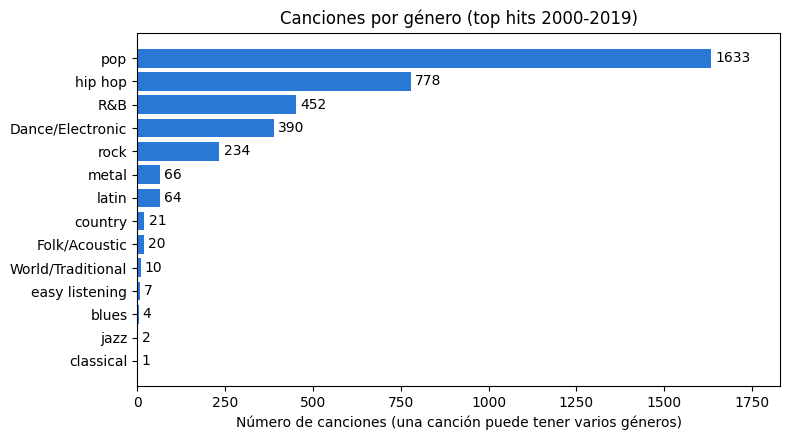

In [3]:
generos = df["genre"].str.split(", ").explode()   # "rock, pop" -> dos filas
generos = generos[generos != "set()"]             # quitamos las canciones sin género
conteo = generos.value_counts()

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.barh(conteo.index, conteo.values, color="#2a78d6")
ax.invert_yaxis()
ax.bar_label(barras, padding=3)
ax.set_xlim(0, conteo.max() * 1.12)
ax.set_xlabel("Número de canciones (una canción puede tener varios géneros)")
ax.set_title("Canciones por género (top hits 2000-2019)")
plt.tight_layout()
plt.show()

### Versión con seaborn

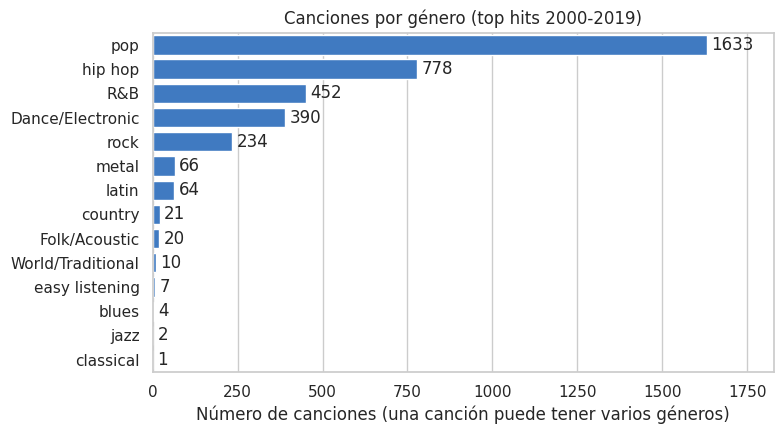

In [4]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=conteo.values, y=conteo.index, color="#2a78d6", ax=ax)
ax.bar_label(ax.containers[0], padding=3)
ax.set_xlim(0, conteo.max() * 1.12)
ax.set_xlabel("Número de canciones (una canción puede tener varios géneros)")
ax.set_ylabel("")
ax.set_title("Canciones por género (top hits 2000-2019)")
plt.tight_layout()
plt.show()

**Resultado.** El género más frecuente es **pop** (1633 canciones, el 81,65 % de las 2000), seguido de **hip hop** (778), **R&B** (452), **Dance/Electronic** (390) y **rock** (234). Los géneros minoritarios (classical, jazz, blues) tienen entre 1 y 4 canciones, así que no se puede concluir nada sobre ellos.

**Limitación.** El reparto depende de cómo Spotify etiqueta cada canción, y un mismo tema puede tener varios géneros; por eso las barras no suman 2000.

## 3. Gráfico 2: popularidad media por año (línea)

**Qué muestra.** La popularidad media (de 0 a 100) de las canciones de cada año. Una línea es lo adecuado para ver la evolución en el tiempo.

**Cómo leerlo.** Cada punto es la media de un año. En la versión de seaborn, la **banda sombreada** es el intervalo de confianza al 95 %: indica cuánta incertidumbre tiene esa media. Si las bandas de dos años se solapan, la diferencia entre ellos puede ser simple ruido.

### Versión con matplotlib

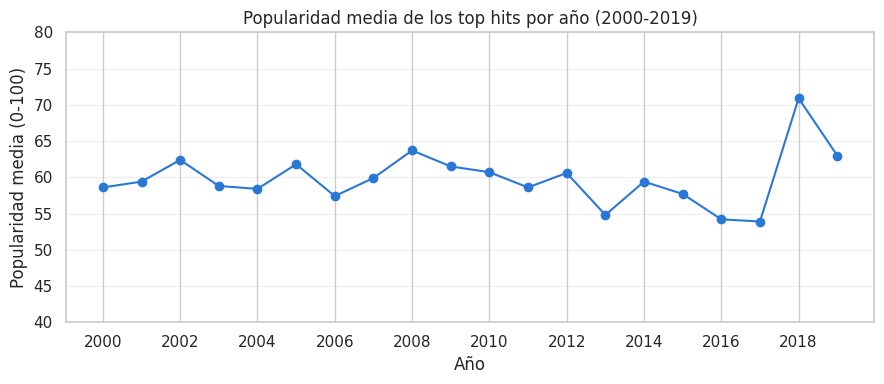

In [5]:
por_anio = d.groupby("year")["popularity"].mean().round(1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(por_anio.index, por_anio.values, marker="o", color="#2a78d6")
ax.set_xticks(range(2000, 2020, 2))
ax.set_ylim(40, 80)
ax.set_xlabel("Año")
ax.set_ylabel("Popularidad media (0-100)")
ax.set_title("Popularidad media de los top hits por año (2000-2019)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Versión con seaborn

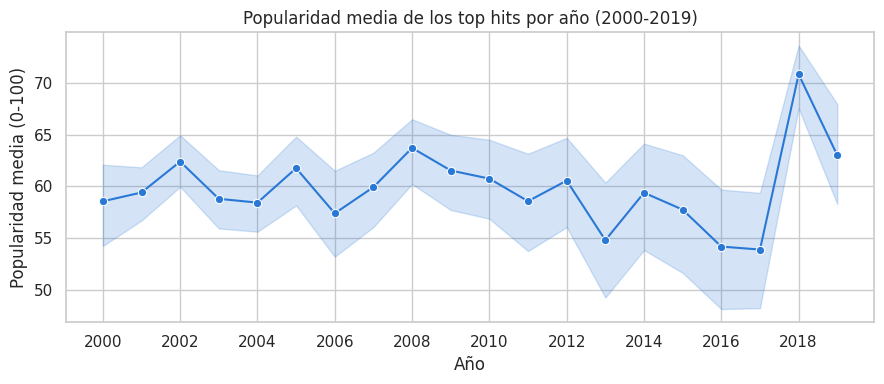

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(data=d, x="year", y="popularity", estimator="mean",
             errorbar=("ci", 95), marker="o", color="#2a78d6", ax=ax)
ax.set_xticks(range(2000, 2020, 2))
ax.set_xlabel("Año")
ax.set_ylabel("Popularidad media (0-100)")
ax.set_title("Popularidad media de los top hits por año (2000-2019)")
plt.tight_layout()
plt.show()

**Resultado.** La popularidad media se mueve entre unos 54 y 64 puntos casi todos los años. La excepción es **2018, con 70,9**, frente a 53,9 en 2017. Es el único año cuya banda de confianza queda claramente por encima de la del año anterior; el resto de subidas y bajadas caen dentro de las bandas y no se pueden distinguir del ruido.

**Limitaciones.** (1) El eje vertical de la versión matplotlib empieza en 40, no en 0, lo que hace que las diferencias parezcan mayores; es aceptable para ver una tendencia, pero hay que tenerlo en cuenta. (2) No sabemos por qué ocurre el pico de 2018. Una posibilidad, **no comprobada**, es que la popularidad se haya medido en un momento concreto y no en el año de lanzamiento de cada canción.

## 4. Gráfico 3: duración frente a popularidad (dispersión)

**Qué muestra.** Cada punto es una canción: su duración en minutos (eje X) y su popularidad (eje Y). La dispersión sirve para ver si dos variables numéricas están relacionadas.

**Cómo leerlo.** Si los puntos formaran una nube inclinada hacia arriba, las canciones más largas serían más populares; si forman una nube sin forma, no hay relación. Los puntos se dibujan semitransparentes porque, con casi 2000, se solapan. En seaborn se añade la **recta de tendencia** y se colorea por si la canción es explícita.

### Versión con matplotlib

count    1958.00
mean        3.80
std         0.65
min         1.88
25%         3.39
50%         3.72
75%         4.12
max         8.07
Name: duracion_min, dtype: float64
Correlación duración-popularidad: 0.051


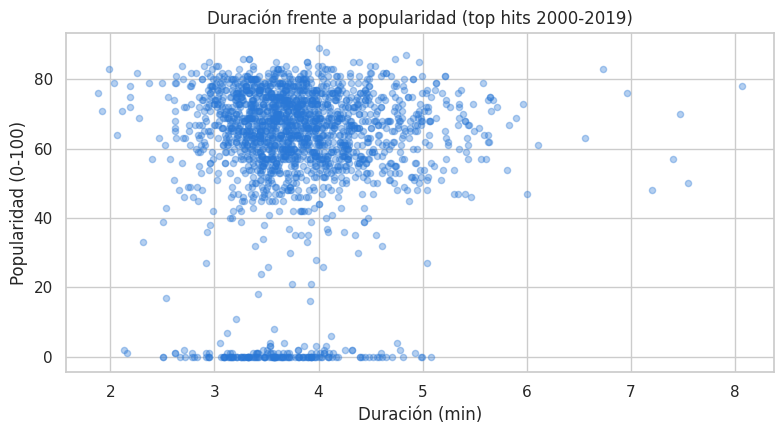

In [7]:
print(d["duracion_min"].describe().round(2))
print("Correlación duración-popularidad:", round(d["duracion_min"].corr(d["popularity"]), 3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(d["duracion_min"], d["popularity"], alpha=0.35, s=20, color="#2a78d6")
ax.set_xlabel("Duración (min)")
ax.set_ylabel("Popularidad (0-100)")
ax.set_title("Duración frente a popularidad (top hits 2000-2019)")
plt.tight_layout()
plt.show()

### Versión con seaborn

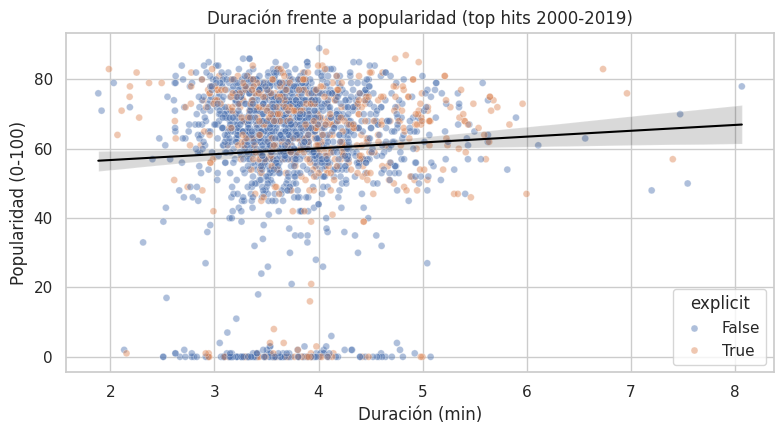

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.scatterplot(data=d, x="duracion_min", y="popularity", hue="explicit",
                alpha=0.45, s=25, ax=ax)
sns.regplot(data=d, x="duracion_min", y="popularity", scatter=False,
            color="black", line_kws={"linewidth": 1.5}, ax=ax)
ax.set_xlabel("Duración (min)")
ax.set_ylabel("Popularidad (0-100)")
ax.set_title("Duración frente a popularidad (top hits 2000-2019)")
plt.tight_layout()
plt.show()

**Resultado.** Se usan 1958 canciones (2000-2019). La duración media es de 3,80 min (mediana 3,72); la mitad central de las canciones dura entre 3,39 y 4,12 min, y los extremos son 1,88 y 8,07 min. La **correlación es 0,051**, es decir, prácticamente nula: la duración casi no explica la popularidad. La recta de seaborn sube muy ligeramente, pero su banda de confianza es ancha, sobre todo a la derecha, donde hay pocas canciones largas.

**Dato a tener en cuenta.** Se ve un grupo de canciones con **popularidad igual a 0**, separado del resto. Estas canciones están en la lista de éxitos, así que probablemente no sean realmente impopulares, sino canciones sin dato de popularidad (**hipótesis, no verificada**). La celda siguiente cuenta cuántas son y cómo cambia la correlación sin ellas.

In [9]:
ceros = d[d["popularity"] == 0]
print("Canciones con popularidad 0:", len(ceros), "de", len(d))
print("Correlación sin esos ceros:",
      round(d.loc[d["popularity"] > 0, "duracion_min"].corr(d.loc[d["popularity"] > 0, "popularity"]), 3))
print("\nCanciones con popularidad 0, por año:")
print(ceros.groupby("year").size().to_string())

Canciones con popularidad 0: 126 de 1958
Correlación sin esos ceros: -0.003

Canciones con popularidad 0, por año:
year
2000     2
2001     2
2003     2
2005     4
2006     6
2007     3
2008     2
2009     1
2010     6
2011     6
2012    12
2013    13
2014    13
2015    13
2016    18
2017    19
2018     1
2019     3


## 5. Gráfico 4: distribución de la duración (histograma)

**Qué muestra.** Cuántas canciones caen en cada intervalo de duración. El histograma sirve para ver la forma de una variable numérica: dónde se concentra y si tiene colas.

**Cómo leerlo.** La altura de cada columna es el número de canciones de ese intervalo. Las líneas verticales marcan la media y la mediana. En la versión de seaborn se añade la curva suavizada (KDE).

### Versión con matplotlib

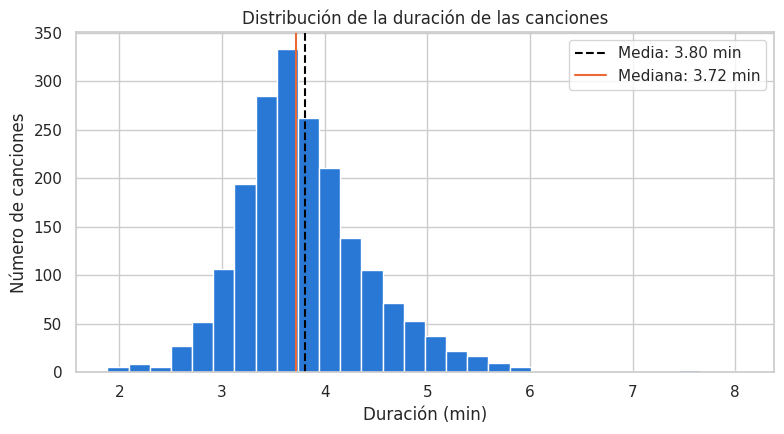

In [10]:
media = d["duracion_min"].mean()
mediana = d["duracion_min"].median()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(d["duracion_min"], bins=30, color="#2a78d6", edgecolor="white")
ax.axvline(media, color="black", linestyle="--", label=f"Media: {media:.2f} min")
ax.axvline(mediana, color="#eb6834", linestyle="-", label=f"Mediana: {mediana:.2f} min")
ax.set_xlabel("Duración (min)")
ax.set_ylabel("Número de canciones")
ax.set_title("Distribución de la duración de las canciones")
ax.legend()
plt.tight_layout()
plt.show()

### Versión con seaborn

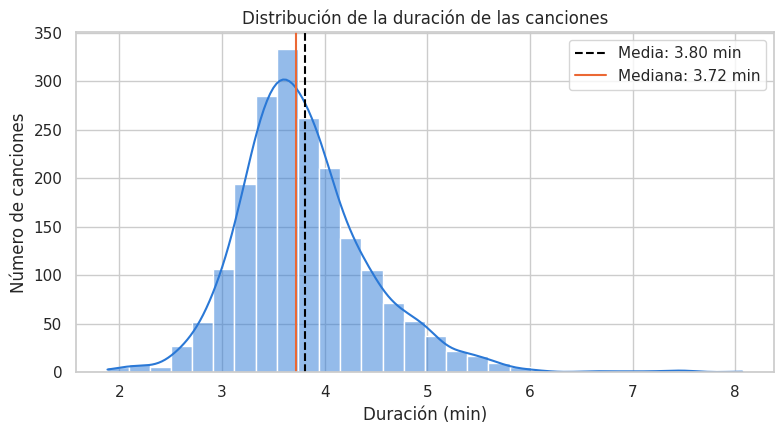

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=d, x="duracion_min", bins=30, kde=True, color="#2a78d6", ax=ax)
ax.axvline(media, color="black", linestyle="--", label=f"Media: {media:.2f} min")
ax.axvline(mediana, color="#eb6834", linestyle="-", label=f"Mediana: {mediana:.2f} min")
ax.set_xlabel("Duración (min)")
ax.set_ylabel("Número de canciones")
ax.set_title("Distribución de la duración de las canciones")
ax.legend()
plt.tight_layout()
plt.show()

**Resultado.** La mayoría de las canciones dura entre 3,4 y 4,1 minutos (la mitad central), con media 3,80 y mediana 3,72 min. La media queda algo por encima de la mediana porque hay una **cola hacia la derecha**: unas pocas canciones muy largas (hasta 8,07 min) tiran de la media hacia arriba.

**Limitación.** El aspecto del histograma depende del número de intervalos (`bins`); aquí se usan 30, pero con otro valor las columnas cambiarían de forma, aunque la conclusión general es la misma.

## 6. Gráfico 5: porcentaje de canciones explícitas por año (barras apiladas al 100 %)

**Qué muestra.** Para cada año, qué parte de las canciones son explícitas y qué parte no. Cada barra suma el 100 %, así que se compara el **reparto**, no el número de canciones.

**Cómo leerlo.** La altura del segmento naranja es el porcentaje de canciones explícitas de ese año. No indica cuántas canciones hay: para eso hay que mirar la tabla de resumen del principio (hay unas 100 por año).

### Versión con matplotlib

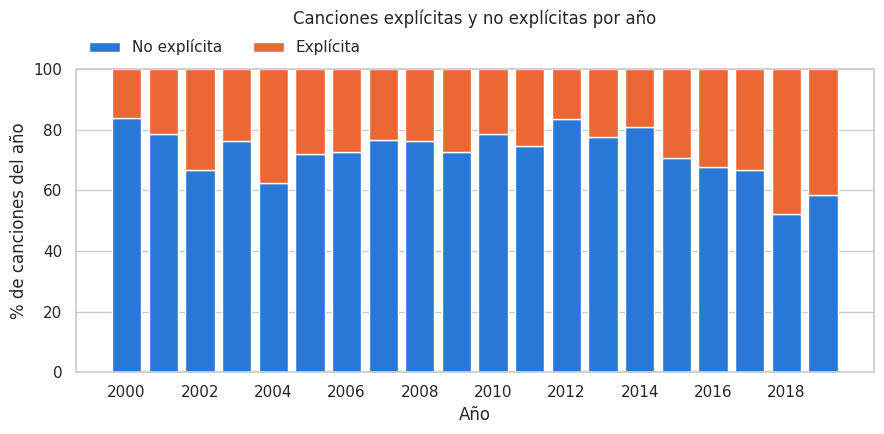

In [12]:
tabla = pd.crosstab(d["year"], d["explicit"], normalize="index") * 100   # % por año
tabla = tabla.rename(columns={False: "No explícita", True: "Explícita"})

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(tabla.index, tabla["No explícita"], color="#2a78d6", label="No explícita")
ax.bar(tabla.index, tabla["Explícita"], bottom=tabla["No explícita"],
       color="#eb6834", label="Explícita")
ax.set_xticks(range(2000, 2020, 2))
ax.set_ylim(0, 100)
ax.set_xlabel("Año")
ax.set_ylabel("% de canciones del año")
ax.set_title("Canciones explícitas y no explícitas por año", pad=32)
ax.legend(ncols=2, loc="lower left", bbox_to_anchor=(0, 1.0), frameon=False)
plt.tight_layout()
plt.show()

### Versión con seaborn

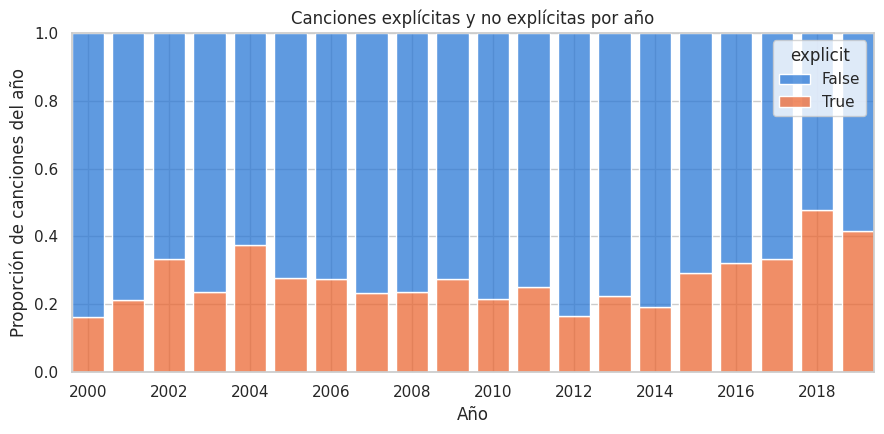

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=d, x="year", hue="explicit", multiple="fill", discrete=True,
             palette={False: "#2a78d6", True: "#eb6834"}, shrink=0.8, ax=ax)
ax.set_xticks(range(2000, 2020, 2))
ax.set_xlabel("Año")
ax.set_ylabel("Proporción de canciones del año")
ax.set_title("Canciones explícitas y no explícitas por año")
plt.tight_layout()
plt.show()

In [ ]:
# Lectura de los datos (se calcula a partir de la tabla de arriba)
exp = tabla["Explícita"].round(1)
print(f"Explícitas en {exp.index.min()}: {exp.iloc[0]} %")
print(f"Explícitas en {exp.index.max()}: {exp.iloc[-1]} %")
print(f"Año con más explícitas: {exp.idxmax()} ({exp.max()} %)")
print(f"Año con menos explícitas: {exp.idxmin()} ({exp.min()} %)")

**Resultado.** El porcentaje de canciones explícitas pasa de ~16 % en 2000 a un máximo de ~48 % en 2018 (en 2019 baja a ~41 %). La subida no es constante: hay picos aislados (por ejemplo, 2004) y años con porcentajes bajos (2012 y 2014), y el aumento sostenido empieza hacia 2014-2015. Coincide que 2018 es también el año con mayor popularidad media (gráfico 2), pero con estos datos no se puede afirmar que una cosa explique la otra.

**Limitaciones.** Con unas 100 canciones por año, un cambio de pocos puntos porcentuales equivale a unas pocas canciones y puede ser ruido. Además, que haya más canciones explícitas en los éxitos no significa que se publiquen más: el conjunto solo incluye las canciones que llegaron a lo más alto.

## 7. Conclusiones

- **Género:** el pop domina los éxitos (aparece en el 81,65 % de las canciones), seguido de hip hop, R&B, Dance/Electronic y rock.
- **Tiempo:** la popularidad media apenas cambia entre 2000 y 2019, salvo un pico en 2018 cuyo motivo no podemos explicar con estos datos.
- **Duración:** casi no influye en la popularidad (correlación de 0,051), y la mayoría de canciones dura entre 3,4 y 4,1 minutos.
- **Calidad de los datos:** hay valores que conviene revisar (canciones sin género y canciones con popularidad 0), y se han tratado como se explica en cada apartado.
- **Herramientas:** matplotlib da control total sobre cada detalle, pero hay que escribir más código; seaborn simplifica los gráficos estadísticos (bandas de confianza, histogramas con KDE, colores por categoría) con menos líneas.

**Siguiente paso:** estos mismos gráficos se muestran de forma interactiva en la aplicación de Streamlit (`app.py`).